In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

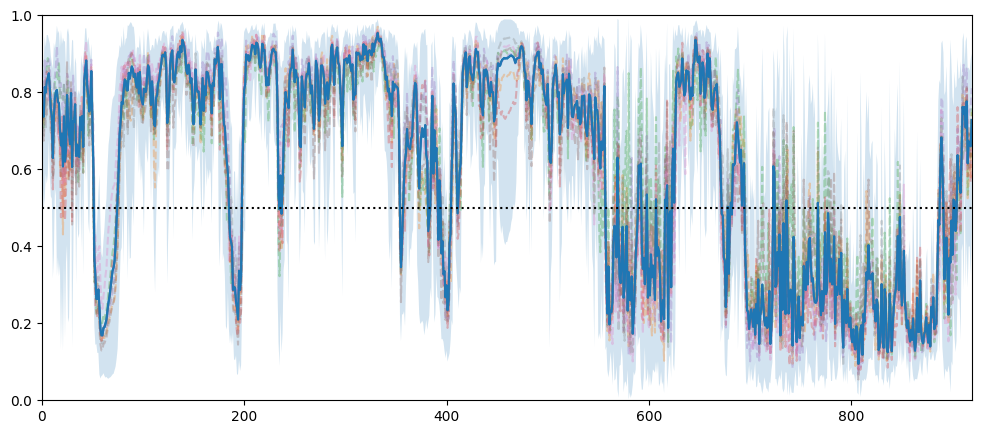

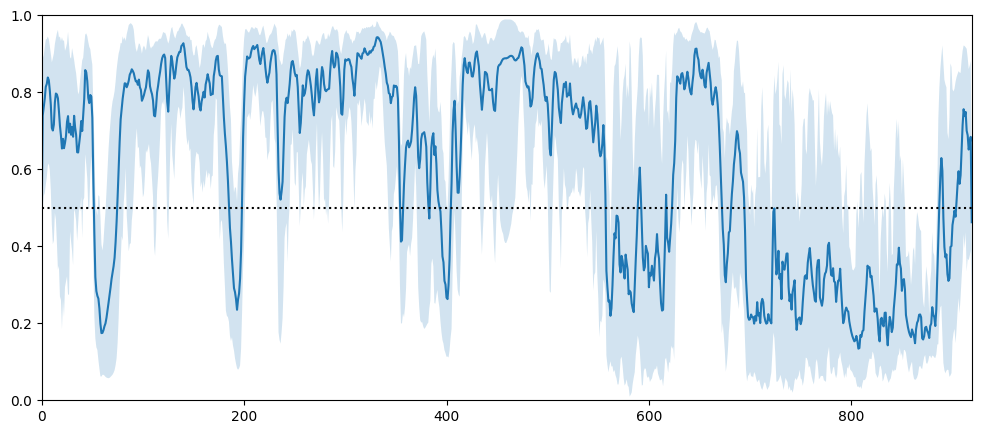

In [14]:
df = pd.read_csv(
    "ar-adopt2g.csv",
    index_col="label",
    converters={
        "gscores": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.asarray(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.asarray(json.loads(x), dtype=float),
    },
)
gscores = df.loc["AR_full", "gscores"]
gscores_lower = df.loc["AR_full", "gscores_lower"]
gscores_upper = df.loc["AR_full", "gscores_upper"]
member_gscores = df.loc["AR_full", "member_gscores"]

plt.figure(figsize=(12, 5))
plt.plot(gscores)
plt.fill_between(range(len(gscores)), gscores_lower, gscores_upper, alpha=0.2)
plt.plot(member_gscores.T, alpha=0.3, ls="--")
plt.plot(gscores, c="C0")
plt.axhline(0.5, color="k", linestyle=":")
plt.ylim(0, 1)
plt.margins(x=0)
plt.show()

plt.figure(figsize=(12, 5))
# Smooth gscores and bounds with a window of 3
window = 3


def smooth(x, window):
    return np.convolve(x, np.ones(window) / window, mode="same")


gscores_smooth = smooth(gscores, window)
gscores_lower_smooth = smooth(gscores_lower, window)
gscores_upper_smooth = smooth(gscores_upper, window)

plt.plot(gscores_smooth)
plt.fill_between(range(len(gscores)), gscores_lower_smooth, gscores_upper_smooth, alpha=0.2)
plt.axhline(0.5, color="k", linestyle=":")
plt.ylim(0, 1)
plt.margins(x=0)
plt.show()

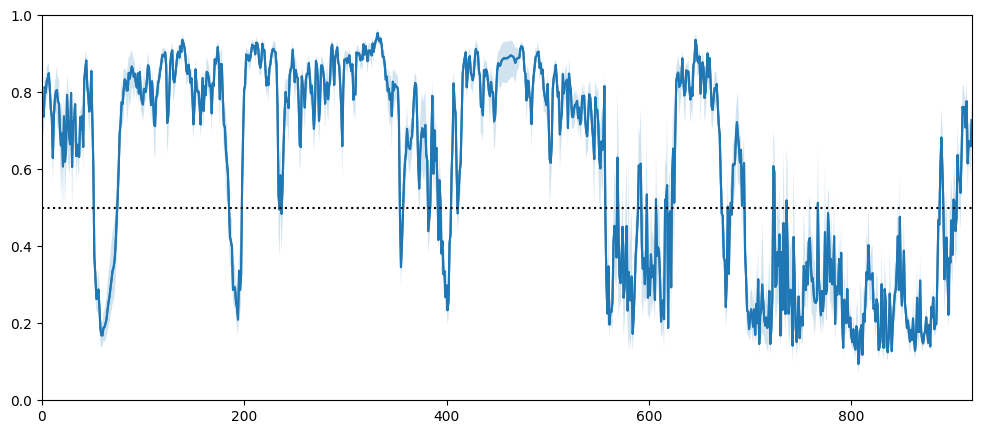

In [10]:
df = pd.read_csv(
    "ar-adopt2g-no.csv",
    index_col="label",
    converters={
        "gscores": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_lower": lambda x: np.asarray(json.loads(x), dtype=float),
        "gscores_upper": lambda x: np.asarray(json.loads(x), dtype=float),
        "member_gscores": lambda x: np.asarray(json.loads(x), dtype=float),
    },
)
gscores = df.loc["AR_full", "gscores"]
gscores_lower = df.loc["AR_full", "gscores_lower"]
gscores_upper = df.loc["AR_full", "gscores_upper"]
# member_gscores = df.loc["AR_full", "member_gscores"]

plt.figure(figsize=(12, 5))
plt.plot(gscores)
plt.fill_between(range(len(gscores)), gscores_lower, gscores_upper, alpha=0.2)
# plt.plot(member_gscores.T, alpha=0.5)
plt.plot(gscores, c="C0")
plt.axhline(0.5, color="k", linestyle=":")
plt.ylim(0, 1)
plt.margins(x=0)
plt.show()